In [63]:
import re
import numpy as np
import matplotlib.pyplot as plt

In [64]:
def parse_dqn_runs(filepath):
    with open(filepath, "r") as f:
        lines = f.readlines()

    runs = []
    current_rewards = []
    current_steps = []

    for line in lines:
        if "=== QDN Run" in line:
            if current_rewards:
                runs.append((current_rewards, current_steps))
                current_rewards, current_steps = [], []
            continue

        match = re.search(r"Episode \d+/\d+, score: (\d+), total_steps: (\d+)", line)
        if match:
            reward = int(match.group(1))
            step = int(match.group(2))
            current_rewards.append(reward)
            current_steps.append(step)

    # Add last run
    if current_rewards:
        runs.append((current_rewards, current_steps))

    return runs


In [17]:
dqn_runs = parse_dqn_runs("qdn.txt")

In [65]:
import pickle

with open("ac_results.pkl", "rb") as f:
    ac_runs = pickle.load(f)

with open("a2c_results.pkl", "rb") as f:
    a2c_runs = pickle.load(f)

with open("ppo_results.pkl", "rb") as f:
    ppo_runs = pickle.load(f)


In [56]:
def parse_ppo_log(filepath):
    runs = []
    current_steps = []
    current_rewards = []

    with open(filepath, 'r') as f:
        for line in f:
            if "=== Run" in line:
                if current_steps:
                    runs.append((np.array(current_rewards), np.array(current_steps)))
                    current_steps, current_rewards = [], []
                continue

            match = re.search(r"Step (\d+)/\d+ \| Reward: ([\d.]+)", line)
            if match:
                step = int(match.group(1))
                reward = float(match.group(2))
                current_steps.append(step)
                current_rewards.append(reward)

    if current_steps:
        runs.append((np.array(current_rewards), np.array(current_steps)))

    return runs


In [57]:
ppo_runs = parse_ppo_log("ppo_105.txt")

In [ ]:
def plot_learning_curve_uniform_steps(dqn_runs=None, ac_runs=None, a2c_runs=None, ppo_runs=None,
                                      window_size=50, max_env_steps=100_000,
                                      title="Result Comparison of DQN, AC, A2C, PPO"):
    plt.figure(figsize=(10, 6))

    def process_and_plot(runs, label, color):
        x_target = np.linspace(0, max_env_steps, 1000)
        all_interp_rewards = []

        for rewards, steps in runs:
            rewards = np.array(rewards)
            steps = np.array(steps)

            if len(rewards) >= window_size:
                smoothed_rewards = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')
                smoothed_steps = steps[window_size - 1:]
            else:
                smoothed_rewards = rewards
                smoothed_steps = steps

            # interpolate to fixed x axis
            interp_rewards = np.interp(x_target, smoothed_steps, smoothed_rewards)
            all_interp_rewards.append(interp_rewards)

        mean_reward = np.mean(all_interp_rewards, axis=0)
        plt.plot(x_target, mean_reward, label=label, color=color, linewidth=2)

    if dqn_runs:
        process_and_plot(dqn_runs, "DQN", "green")
    if ac_runs:
        process_and_plot(ac_runs, "AC", "red")
    if a2c_runs:
        process_and_plot(a2c_runs, "A2C", "orange")
    if ppo_runs:
        process_and_plot(ppo_runs, "PPO", "purple")

    plt.xlim(0, max_env_steps)
    plt.xlabel("Environment Step")
    plt.ylabel(f"Smoothed Reward (window={window_size})")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()



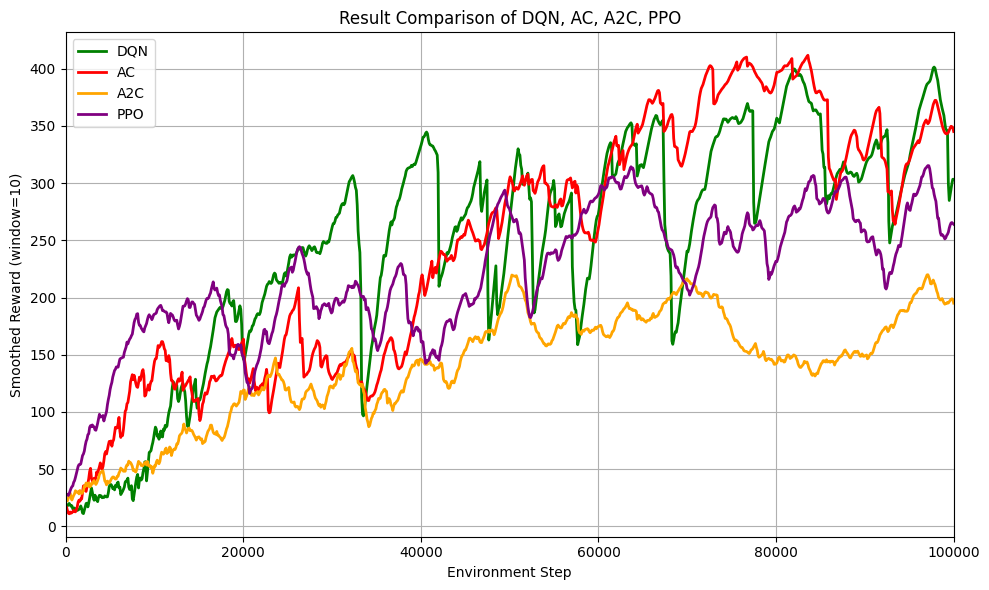

In [62]:
plot_learning_curve_uniform_steps(
    dqn_runs=dqn_runs,
    ac_runs=ac_runs,
    a2c_runs=a2c_runs,
    ppo_runs=ppo_runs,
    window_size=10
)

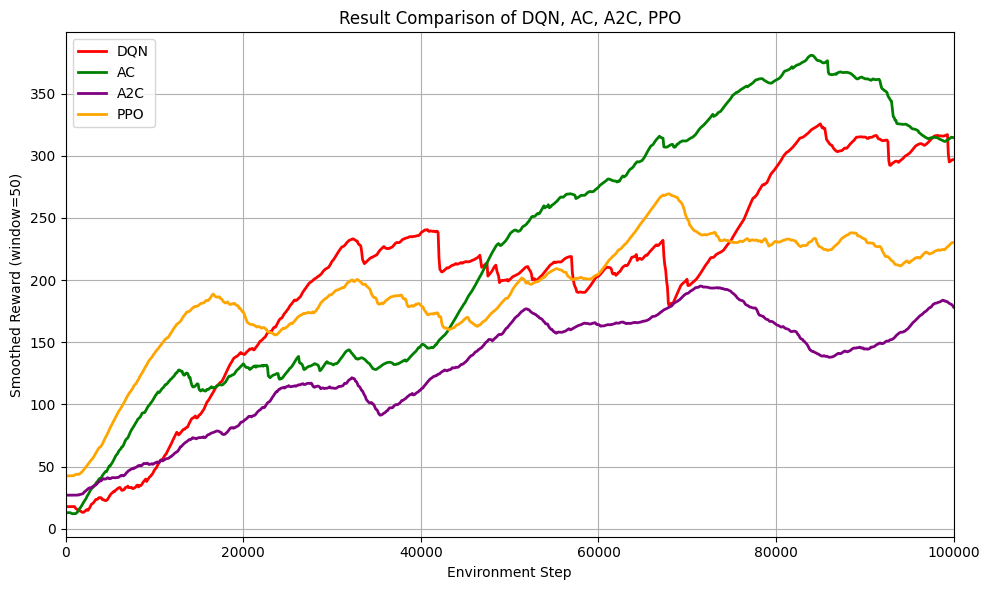

In [59]:
plot_learning_curve_uniform_steps(
    dqn_runs=dqn_runs,
    ac_runs=ac_runs,
    a2c_runs=a2c_runs,
    ppo_runs=ppo_runs,
    window_size=50
)

In [ ]:
def parse_all_log_file(filepath, tag):
    runs = []
    current_steps = []
    current_rewards = []

    with open(filepath, "r") as f:
        for line in f:
            if f"=== {tag}" in line:
                if current_steps:
                    runs.append((np.array(current_rewards), np.array(current_steps)))
                    current_steps, current_rewards = [], []
                continue

            if tag == "PPO":
                match = re.search(r"Step (\d+)/[\d.]+ \| Avg Reward \(last 10\): ([\d.]+)", line)
            else:
                match = re.search(rf"\[{tag}\] Step (\d+)/[\d.]+ \| Reward: ([\d.]+)", line)

            if match:
                step = float(match.group(1))
                reward = float(match.group(2))
                current_steps.append(step)
                current_rewards.append(reward)

    # Add final run
    if current_steps:
        runs.append((np.array(current_rewards), np.array(current_steps)))

    return runs


In [69]:
ppo_runs = parse_all_log_file("ppo_sgd_106.txt", "PPO")
ac_runs = parse_all_log_file("ac_106.txt", "AC")
a2c_runs = parse_all_log_file("a2c_106.txt", "A2C")

In [ ]:
def plot_average_curves(runs_dict, max_steps=1_000_000, window_size=50):
    plt.figure(figsize=(10, 6))
    x_target = np.linspace(0, max_steps, 1000)

    color_map = {
        "PPO with SGD": "purple",
        "AC": "red",
        "A2C": "orange"
    }

    for label, runs in runs_dict.items():
        all_interpolated = []
        for rewards, steps in runs:
            if len(rewards) >= window_size:
                rewards = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')
                steps = steps[window_size - 1:]
            interp = np.interp(x_target, steps, rewards)
            all_interpolated.append(interp)

        avg_reward = np.mean(all_interpolated, axis=0)
        color = color_map.get(label, None)
        plt.plot(x_target, avg_reward, label=label, color=color, linewidth=2)

    plt.xlabel("Environment Steps")
    plt.ylabel("Reward")
    plt.title("Average Learning Curves (5 Runs, 1M Steps)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



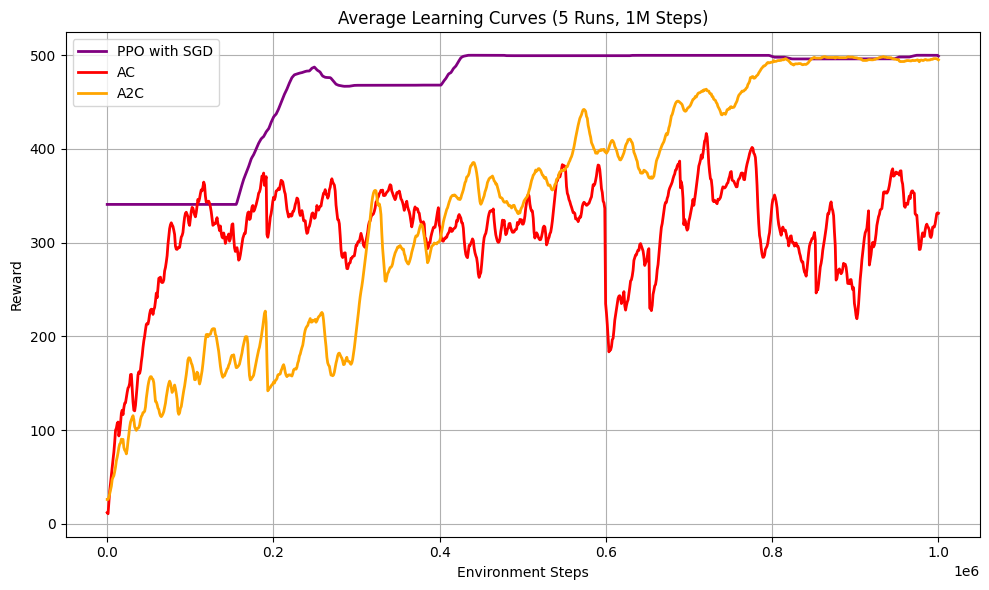

In [83]:
plot_average_curves({
    "PPO with SGD": ppo_runs,
    "AC": ac_runs,
    "A2C": a2c_runs
})